# Lab 4: Linear Regression


In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score

df = pd.read_csv("/content/df_final_features.csv")
df_reg = df.dropna(subset=['Height', 'Weight', 'Age'])

### 1. Simple Linear Regression
This model tests the direct linear relationship between a single independent variable (Height) and the dependent target variable (Weight). The graph displays the line of best fit through the actual data points.

Coefficient (Slope): 1.09
Intercept: -119.90
Mean Squared Error (MSE): 75.06
R-squared Score: 0.63


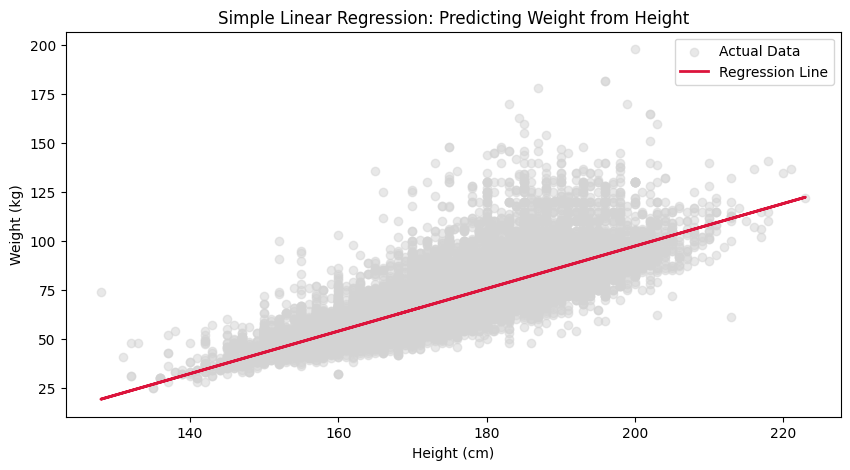

In [ ]:
X_simple = df_reg[['Height']]
y_simple = df_reg['Weight']

X_train_s, X_test_s, y_train_s, y_test_s = train_test_split(X_simple, y_simple, test_size=0.2, random_state=42)

model_simple = LinearRegression()
model_simple.fit(X_train_s, y_train_s)

y_pred_s = model_simple.predict(X_test_s)

print(f"Coefficient (Slope): {model_simple.coef_[0]:.2f}")
print(f"Intercept: {model_simple.intercept_:.2f}")
print(f"Mean Squared Error (MSE): {mean_squared_error(y_test_s, y_pred_s):.2f}")
print(f"R-squared Score: {r2_score(y_test_s, y_pred_s):.2f}")

plt.figure(figsize=(10, 5))
plt.scatter(X_test_s, y_test_s, color='lightgray', alpha=0.5, label='Actual Data')
plt.plot(X_test_s, y_pred_s, color='crimson', linewidth=2, label='Regression Line')
plt.title('Simple Linear Regression: Predicting Weight from Height')
plt.xlabel('Height (cm)')
plt.ylabel('Weight (kg)')
plt.legend()
plt.show()

### 2. Multiple Linear Regression
This model evaluates how multiple independent variables simultaneously impact the continuous target variable.

In [ ]:
X_multi = df_reg[['Height', 'Age']]
y_multi = df_reg['Weight']

X_train_m, X_test_m, y_train_m, y_test_m = train_test_split(X_multi, y_multi, test_size=0.2, random_state=42)

model_multi = LinearRegression()
model_multi.fit(X_train_m, y_train_m)

y_pred_m = model_multi.predict(X_test_m)

print("Coefficients:")
print(f"  - Height Impact: {model_multi.coef_[0]:.2f} kg per cm")
print(f"  - Age Impact: {model_multi.coef_[1]:.2f} kg per year")
print(f"Intercept: {model_multi.intercept_:.2f}")
print(f"Mean Squared Error (MSE): {mean_squared_error(y_test_m, y_pred_m):.2f}")
print(f"R-squared Score: {r2_score(y_test_m, y_pred_m):.2f}")

Coefficients:
  - Height Impact: 1.07 kg per cm
  - Age Impact: 0.26 kg per year
Intercept: -122.87
Mean Squared Error (MSE): 73.13
R-squared Score: 0.64
